#DSA495 - Topic Model Project

This code file will run a topic model analysis on open ended survey responses. The survey was ran in spring of 2026 and respondents were asked to indicate their opinions on a bipartisan bill to limit Supreme Court justices terms to 20 years.

In [1]:
%pip install -q "bertopic==0.17.4" "sentence-transformers>=3,<7" "pandas>=2.2,<3" "plotly>=6,<8"

In [2]:
from pathlib import Path
import os
import random

import numpy as np
import pandas as pd
import torch
from bertopic import BERTopic
from hdbscan import HDBSCAN
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP

# Document Collection and Upload.
The code below uploads the csv for open ended survey response answers. Specifically, it is responses from the constitutional amendment treatment.


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
DATA_DIR = Path("/content/drive/MyDrive/DSA-TextAnalysis/ProjectData")

q145_con = pd.read_csv(DATA_DIR / "con.csv")

# Topic Model Analysis

In [6]:
documents = q145_con["response"].tolist()

random.seed(42)
# Convert documents to string and handle any potential NaN values to prevent future errors
documents = [str(doc) for doc in documents]

np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(1)

EMBEDDING_MODEL = "all-MiniLM-L6-v2"
EMBEDDING_REVISION = "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"
embedding_model = SentenceTransformer(
    EMBEDDING_MODEL,
    revision=EMBEDDING_REVISION,
    device="cpu",
)
embeddings = embedding_model.encode(documents, show_progress_bar=True)

embeddings.shape

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

(331, 384)

In [7]:
umap_model = UMAP(          # Creates a model for reducing embedding dimensions.
    n_neighbors=12,         # Considers 12 nearby documents when preserving structure.
    n_components=5,         # Reduces each embedding to 5 dimensions.
    min_dist=0.0,           # Allows similar documents to be packed tightly together.
    metric="cosine",        # Measures similarity using vector direction.
    random_state=42,        # Makes results reproducible.
)

vectorizer_model = CountVectorizer(  # Converts topic documents into word-count features.
    stop_words="english",            # Removes common English words.
    ngram_range=(1, 2),              # Uses single words and two-word phrases.
    min_df=3,                        # Keeps terms appearing in at least 3 documents.
)

hdbscan_model = HDBSCAN(             # Groups similar documents into clusters.
    min_cluster_size=10,             # Requires at least 25 documents per cluster.
    min_samples=5,                   # Controls how conservative the clustering is.
    metric="euclidean",              # Uses straight-line distance after UMAP.
    cluster_selection_method="eom",  # Selects stable, persistent clusters.
    prediction_data=True,            # Saves information needed to classify new documents.
    core_dist_n_jobs=1,              # Uses one CPU job for core-distance calculations.
)

topic_model = BERTopic(                       # Creates the complete topic-modeling pipeline.
    embedding_model=embedding_model,          # Converts text into semantic embeddings.
    umap_model=umap_model,                    # Uses the configured dimension-reduction model.
    hdbscan_model=hdbscan_model,              # Uses the configured clustering model.
    vectorizer_model=vectorizer_model,        # Uses the configured word-count model.
    top_n_words=8,                            # Shows the top 8 words for each topic.
    verbose=True,
)

In [8]:
topics, probabilities = topic_model.fit_transform(
    documents,   # First argument: the original text documents
    embeddings   # Second argument: the document embedding vectors
)  # Fits BERTopic and assigns a topic and probability to each document.

topic_info = topic_model.get_topic_info() #topic_model is a BERTtopic object
# Creates a summary table containing information about the discovered topics.

topic_info[["Topic", "Count", "Name", "Representation"]]
# Displays selected columns: topic ID, document count, name, and representative words.

2026-11-19 19:24:49,559 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-19 19:25:12,557 - BERTopic - Dimensionality - Completed ✓
2026-11-19 19:25:12,559 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-19 19:25:12,597 - BERTopic - Cluster - Completed ✓
2026-11-19 19:25:12,608 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-19 19:25:12,658 - BERTopic - Representation - Completed ✓


,Topic,Count,Name,Representation
0,-1,96,-1_20_government_people_change,"[20, government, people, change, federal, time..."
1,0,49,0_lifetime_life_appointed_president,"[lifetime, life, appointed, president, people,..."
2,1,38,1_constitution_written_change_changing,"[constitution, written, change, changing, chan..."
3,2,28,2_age_decision_mentally_people,"[age, decision, mentally, people, person, serv..."
4,3,24,3_fresh_feel_ideas_people,"[fresh, feel, ideas, people, world, country, c..."
5,4,24,4_amendment_constitutional_constitutional amen...,"[amendment, constitutional, constitutional ame..."
6,5,20,5_favor_takes_makes sense_answer,"[favor, takes, makes sense, answer, reason, se..."
7,6,15,6_country_power_political_change,"[country, power, political, change, corrupted,..."
8,7,14,7_20_serving_life_serving life,"[20, serving, life, serving life, limited, agr..."
9,8,12,8_time_times_change_times change,"[time, times, change, times change, change peo..."


In [9]:
# 1. Prepare documents and generate their embeddings using correct constitutional variables
documents_con = [str(doc) for doc in q145_con["response"].tolist()]
embeddings_con = embedding_model.encode(documents_con, show_progress_bar=True)

# 2. Fit the topic model specifically on constitutional documents and embeddings
topics_con, probabilities_con = topic_model.fit_transform(
    documents_con,
    embeddings_con
)

# 3. Add them safely to your q145_con dataframe
q145_con['Topic'] = topics_con
q145_con['Probability'] = probabilities_con

# Display the top of the updated dataframe
display(q145_con.head())

Batches:   0%|          | 0/11 [00:00<?, ?it/s]

2026-11-19 19:25:21,562 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-19 19:25:22,311 - BERTopic - Dimensionality - Completed ✓
2026-11-19 19:25:22,312 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-19 19:25:22,327 - BERTopic - Cluster - Completed ✓
2026-11-19 19:25:22,331 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-19 19:25:22,352 - BERTopic - Representation - Completed ✓


,X,pid,question,response,BPconRespScore.x,BPconRespScore.y,Topic,Probability
0,2,fb734f4f-6d17-4259-bf17-85fd77e4c20d,q145,feel seats 2 president power,3.000000,3.000000,-1,0.000000
1,4,8746e77e-9b21-40a4-9526-692b7d937b51,q145,feel world,3.285714,3.285714,3,0.948811
2,6,1e1dbf70-bc26-4ba7-aaab-54e4c414d3f8,q145,favor bill creates fair entire lives antiquate...,2.571429,2.571429,-1,0.000000
3,8,66319847-96fc-4d30-976b-8da3d5dc120d,q145,ould fresh ideas,3.571429,3.571429,3,1.000000
4,9,3dc76852-f533-44b1-8338-a0e9a52d8b3c,q145,feel people age including mental capabilities ...,4.571429,4.571429,2,1.000000


#Bar Chart Topic Visualization

In [10]:
readable_topic_labels = topic_model.generate_topic_labels(
    nr_words=3,          # Uses the top 3 words in each label.
    topic_prefix=True,   # Includes the topic number in each label.
    separator=" · ",     # Separates label elements with a middle dot.
)

readable_topic_labels[0] = "Outliers"
# Renames the outlier topic, which is topic -1.

topic_model.set_topic_labels(readable_topic_labels)
# Applies the custom labels to the topic model.

topic_model.get_topic_info()[["Topic", "Count", "CustomName"]]
# Displays each topic’s ID, document count, and custom label.

,Topic,Count,CustomName
0,-1,96,Outliers
1,0,49,0 · lifetime · life · appointed
2,1,38,1 · constitution · written · change
3,2,28,2 · age · decision · mentally
4,3,24,3 · fresh · feel · ideas
5,4,24,4 · amendment · constitutional · constitutiona...
6,5,20,5 · favor · takes · makes sense
7,6,15,6 · country · power · political
8,7,14,7 · 20 · serving · life
9,8,12,8 · time · times · change


In [13]:
top_topic_ids = topic_info.loc[topic_info["Topic"] != -1, "Topic"].head(8).tolist()

topic_model.visualize_barchart(
    topics=top_topic_ids,
    n_words=6,
    custom_labels=True,
    width=350,   # Increased width to prevent label bunching
    height=320,  # Increased height for better vertical spacing
    title="<b>Distinctive words for Constitutional Treatment</b>",
)

#UMAP Visualization
The code below uses a scattor plot, more specifically a UMAP visulaization to look at the legislation topics.

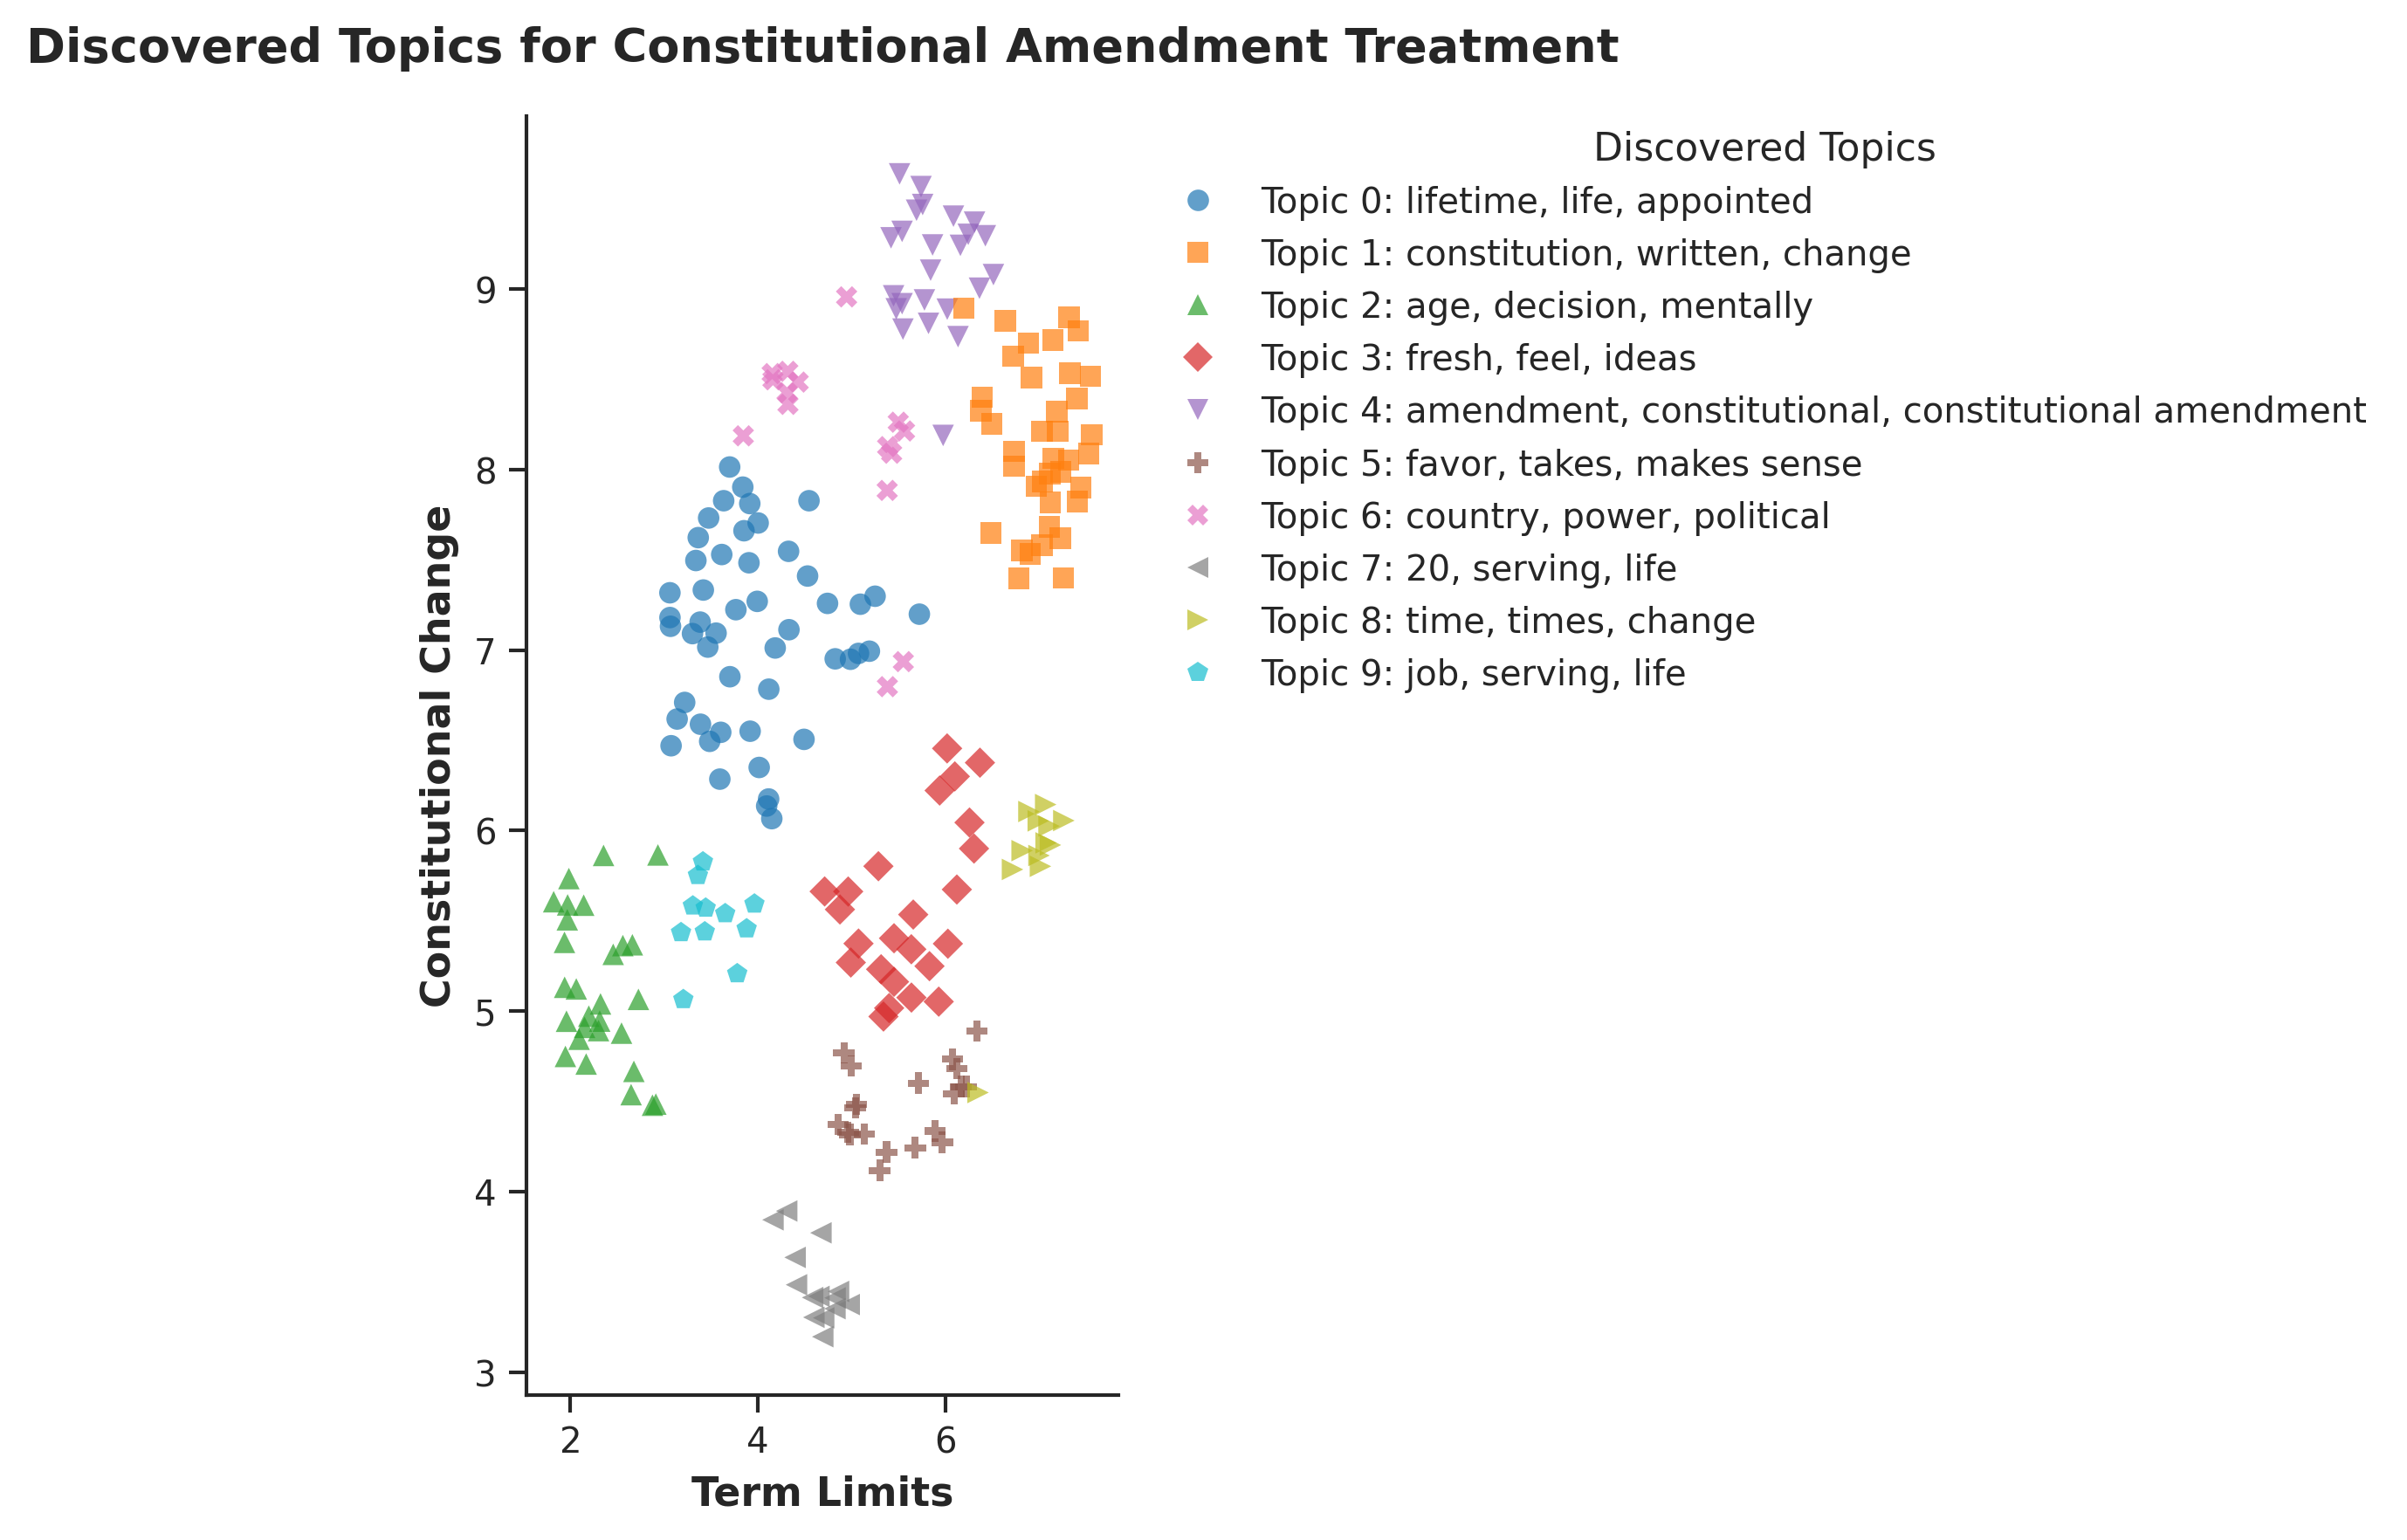

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import umap
import numpy as np
import pandas as pd

# --- 1. Create a Topic-to-Name Mapping Table ---
# We extract the clean top keywords from the "Representation" list for the legend labels
def clean_label(row):
    if row['Topic'] == -1:
        return "Outliers"
    # Join top 3 terms with a comma for a concise legend name
    return f"Topic {row['Topic']}: {', '.join(row['Representation'][:3])}"

topic_info['Clean_Label'] = topic_info.apply(clean_label, axis=1)
label_dict = pd.Series(topic_info.Clean_Label.values, index=topic_info.Topic).to_dict()

# --- 2. Filter out Outliers (-1) from arrays for clean publication clusters ---
embeddings_arr = np.array(embeddings)
topics_arr = np.array(topics)

valid_mask = topics_arr != -1
filtered_embeddings = embeddings_arr[valid_mask]
filtered_topics = topics_arr[valid_mask]

# Convert the numerical topic assignments into their corresponding text labels
text_labels = np.array([label_dict[t] for t in filtered_topics])

# --- 3. Perform UMAP Dimensionality Reduction ---
# 'cosine' metric matches best with text embedding geometries
reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric='cosine', random_state=42)
embedding_2d = reducer.fit_transform(filtered_embeddings)

# --- 4. Define Academic Journal Styling Rules ---
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Liberation Sans', 'DejaVu Sans']
sns.set_context("paper", font_scale=1.1)
sns.set_style("ticks")

# --- 5. Generate Figure (300 DPI with Distinct Shapes) ---
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

unique_sorted_labels = sorted(list(set(text_labels)))
n_topics = len(unique_sorted_labels)

# 1. Define a list of distinct markers (Matplotlib supports these standard shapes)
# Make sure your list has at least as many items as you have unique topics.
available_markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '<', '>', 'p', '*', 'h']
markers_list = available_markers[:n_topics]

# 2. Use 'style' to map shapes and 'markers' to define them
scatter = sns.scatterplot(
    x=embedding_2d[:, 0],
    y=embedding_2d[:, 1],
    hue=text_labels,          # Optional: Keep color so it's easier to distinguish
    style=text_labels,        # <-- Maps categories to different shapes
    markers=markers_list,     # <-- Supplies the custom shape list
    hue_order=unique_sorted_labels,
    style_order=unique_sorted_labels,
    alpha=0.7,
    s=35,                     # Slightly larger size so shapes are clearly visible
    edgecolor='none',
    ax=ax
)

# --- 6. Clean Up Ticks and Layout Borders ---
ax.set_xlabel("Term Limits", fontsize=11, fontweight='bold')
ax.set_ylabel("Constitutional Change", fontsize=11, fontweight='bold')
sns.despine() # Strips top and right border lines

ax.set_title("Discovered Topics for Constitutional Amendment Treatment", fontsize=13, fontweight='bold', pad=15)

# Place the legend to the right so it doesn't overlap text clusters
plt.legend(
    title="Discovered Topics",
    bbox_to_anchor=(1.05, 1),
    loc='upper left',
    borderaxespad=0.,
    frameon=False
)

plt.tight_layout()

# --- 7. Save directly as high-resolution images/vectors ---
plt.savefig("Term Limits.pdf", format="pdf", dpi=300, bbox_inches="tight")
plt.savefig("Constitutional_Change.png", format="png", dpi=300, bbox_inches="tight")
plt.show()

#Results

In [18]:
document_info = topic_model.get_document_info(documents)
# Creates a DataFrame with one row for each document.
# It combines each original document with the topic assignment saved during
# fit_transform(), including the topic number, topic name, custom label,
# top keywords, assignment probability, and whether the document is a
# representative example of its topic.
# The documents must be in the same order as those used to train the model.

results = q145_con.copy()  # Copies the correct original dataset.
results["topic"] = document_info["Topic"]  # Adds each document’s assigned topic ID.
results["topic_label"] = document_info["CustomName"]  # Adds its readable topic label.
results["topic_keywords"] = document_info["Top_n_words"]  # Adds its topic’s main keywords.
results["membership_strength"] = document_info["Probability"]  # Adds HDBSCAN membership strength.
results["representative_document"] = document_info["Representative_document"]  # Marks representative examples.

# Displays the first five selected results using the correct text column 'response'
results[["response", "topic", "topic_label"]].head()

results.topic.value_counts()

,count
topic,
-1,96
0,49
1,38
2,28
3,24
4,24
5,20
6,15
7,14


# c-TF-IDF score
This score measuers how important a word is within a topic. For this analysis, I was interested in understanding if the word constitution or amendment is the most signifagent word because the surevy treatment for this data was the Constitution treatment.  

In [20]:
TOPIC_TO_INSPECT = top_topic_ids[4] # Selects the topic ID to inspect (Topic 4)

topic_words = pd.DataFrame(
    topic_model.get_topic(TOPIC_TO_INSPECT),
    # Gets the topic's important words or phrases and their c-TF-IDF scores.
    columns=["word or phrase", "c-TF-IDF score"],
    # Gives the two resulting columns readable names.
)

representative_articles = results[
    (results["topic"] == TOPIC_TO_INSPECT)
    # Keeps only articles assigned to the selected topic.
    & (results["representative_document"])
    # Further limits the results to articles BERTopic selected as good examples of that topic.
]

display(topic_words.head(8))
# Displays the correct 'response' and 'topic_label' columns instead of 'headline' / 'short_description'
display(representative_articles[["response", "topic_label"]].head())

,word or phrase,c-TF-IDF score
0,amendment,0.189663
1,constitutional,0.114802
2,constitutional amendment,0.108288
3,proposed,0.101403
4,party,0.089366
5,favor,0.085094
6,changing,0.065814
7,laws,0.063698


,response,topic_label
36,favour proposed constitutional amendment estab...,4 · amendment · constitutional · constitutiona...
89,slightly oppose proposed constitutional amendm...,4 · amendment · constitutional · constitutiona...
221,favored proposed constitutional amendment unde...,4 · amendment · constitutional · constitutiona...


The output shows that neither Constitution or amendment have a high c-TF-IDF score. This indicates that the word Constitution does not distingush this topic from others, nor does it dominate within topic 4.

# Outliers

In [21]:
outliers = results[results["topic"] == -1]

outliers.sample(6, random_state=42)[
    ["response", "topic_label", "topic_keywords"]
]

,response,topic_label,topic_keywords
281,equal opportunity car defend equality,Outliers,20 - government - people - change - federal - ...
270,idea 20 federal levels vote approve,Outliers,20 - government - people - change - federal - ...
256,love original history current tenure politics ...,Outliers,20 - government - people - change - federal - ...
321,treated equally matter,Outliers,20 - government - people - change - federal - ...
107,written leave,Outliers,20 - government - people - change - federal - ...
279,bill passed retired ago putting impact experie...,Outliers,20 - government - people - change - federal - ...


The outliers output shows multiple responses that should be left unassigned. Both responses 281 and 270 do not seem to have any direct semantic meaning, as the word choice is sporadic and uninterpretable to a human coder. Response 321, similarly, is not clearly logical for a response to a question about support for Supreme Court term limits. It states, "treated equally matter." It is possible this response could mean justices should have term limits like the other branches of government do, but without more explanation, this cannot be verified, and the response should be left unassigned.
